In [1]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from transformers import GPT2Tokenizer, GPT2Model
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

c:\Users\einav\anaconda3\envs\torch310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
tokenizer = GPT2Tokenizer.from_pretrained("gpt2")
model = GPT2Model.from_pretrained("gpt2", output_hidden_states=True)
model.eval()

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 3363.21it/s]


GPT2Model(
  (wte): Embedding(50257, 768)
  (wpe): Embedding(1024, 768)
  (drop): Dropout(p=0.1, inplace=False)
  (h): ModuleList(
    (0-11): 12 x GPT2Block(
      (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
      (attn): GPT2Attention(
        (c_attn): Conv1D(nf=2304, nx=768)
        (c_proj): Conv1D(nf=768, nx=768)
        (attn_dropout): Dropout(p=0.1, inplace=False)
        (resid_dropout): Dropout(p=0.1, inplace=False)
      )
      (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
      (mlp): GPT2MLP(
        (c_fc): Conv1D(nf=3072, nx=768)
        (c_proj): Conv1D(nf=768, nx=3072)
        (act): NewGELUActivation()
        (dropout): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (ln_f): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
)

In [3]:
# PART A
embedding_matrix = model.wte.weight.detach().numpy()

# first 10,000 tokens
X = embedding_matrix[:10000]

kmeans = KMeans(n_clusters=100, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(X)

tokens = [tokenizer.decode([i]) for i in range(10000)]

df = pd.DataFrame({
    "token_id": range(10000),
    "token": tokens,
    "cluster": cluster_labels
})

df.head()

,token_id,token,cluster
0,0,!,67
1,1,"""",67
2,2,#,67
3,3,$,5
4,4,%,67


In [4]:
for c in range(100):
    cluster_tokens = df[df["cluster"] == c]["token"].tolist()[:30]
    print(f"Cluster {c}: {cluster_tokens}")

Cluster 0: ['The', ' In', ' It', ' He', ' This', ' We', 'In', ' And', ' But', ' You', ' If', 'It', ' As', ' For', ' They', 'We', ' Is', 'This', ' There', ' That', ' How', ' She', ' No', ' So', ' All', ' Or', 'If', 'But', 'He', ' On']
Cluster 1: ['riend', ' friend', ' friends', ' neighbor', ' partners', 'ellow', ' partner', ' client', ' fellow', 'friend', 'mates', ' clients', ' allies', ' colleagues', ' friendly', ' compat', ' Friend', 'mate']
Cluster 2: [' been', ' made', ' found', ' met', ' left', ' done', ' sent', ' started', ' taken', ' lost', ' sold', ' held', ' released', ' received', ' created', ' shot', ' turned', ' killed', ' led', ' decided', ' tried', ' worked', ' built', ' brought', ' increased', ' spent', ' changed', ' gone', ' continued', ' moved']
Cluster 3: [' open', ' hard', ' small', ' clear', ' light', ' short', ' low', ' strong', ' close', ' black', ' quick', ' sound', ' red', ' white', ' wind', ' soft', ' deep', ' hot', ' fast', ' wide', ' slow', ' broad', ' dark', 

In [5]:
selected_clusters = {
    3: "Numbers",
    12: "Names",
    25: "Places",
    41: "Punctuation",
    77: "Common words"
}

In [6]:
selected_df = df[df["cluster"].isin(selected_clusters.keys())].copy()

selected_embeddings = X[selected_df["token_id"].values]

pca_3d = PCA(n_components=3)
coords_3d = pca_3d.fit_transform(selected_embeddings)

selected_df["PC1"] = coords_3d[:, 0]
selected_df["PC2"] = coords_3d[:, 1]
selected_df["PC3"] = coords_3d[:, 2]
selected_df["title"] = selected_df["cluster"].map(selected_clusters)

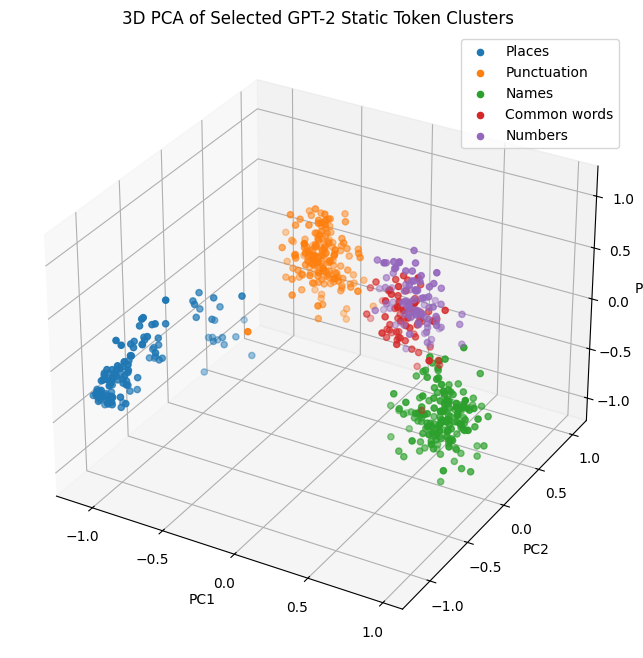

In [7]:
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")

for title in selected_df["title"].unique():
    subset = selected_df[selected_df["title"] == title]
    ax.scatter(subset["PC1"], subset["PC2"], subset["PC3"], label=title, s=20)

ax.set_title("3D PCA of Selected GPT-2 Static Token Clusters")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")
ax.legend()
plt.show()

In [8]:
for cluster_id, title in selected_clusters.items():
    cluster_tokens = df[df["cluster"] == cluster_id]["token"].tolist()[:20]
    print(f"{title}:")
    print(cluster_tokens)
    print()

Numbers:
[' open', ' hard', ' small', ' clear', ' light', ' short', ' low', ' strong', ' close', ' black', ' quick', ' sound', ' red', ' white', ' wind', ' soft', ' deep', ' hot', ' fast', ' wide']

Names:
[' wor', ' whe', ' kn', ' spe', ' bu', ' ke', ' hel', ' stud', ' cour', ' wom', ' cre', ' grou', ' ty', ' tra', ' pri', ' wr', ' eas', ' bre', ' dri', ' chang']

Places:
['5', '6', '7', '8', '9', '00', '01', '000', '10', '12', '50', '19', '11', '20', '201', '30', '15', '14', '16', '13']

Punctuation:
['Q', 'ER', 'IN', 'ON', 'AT', 'AR', 'ES', 'AN', 'EN', 'IS', 'AL', 'AS', 'ED', 'IT', 'IC', 'RE', 'AC', 'ST', 'ID', 'AM']

Common words:
[' car', ' quest', ' bus', ' feat', ' walk', ' track', ' veh', ' road', ' travel', ' engine', ' race', ' door', ' drive', ' mount', ' map', ' vehicle', ' ship', ' tour', ' mission', ' train']



In [9]:
# Part B
target_token = " bank"

finance_sentences = [
    "After receiving my salary, I went to the bank",
    "She opened a savings account at the bank",
    "The company asked for a loan from the bank",
    "He deposited cash at the bank",
    "They discussed interest rates with the bank"
]

river_sentences = [
    "After the flood, we walked along the bank",
    "The fisherman sat quietly on the bank",
    "The children played near the river bank",
    "The boat was tied to the muddy bank",
    "Wild flowers grew beside the bank"
]

sentences = finance_sentences + river_sentences
labels = ["finance"] * 5 + ["river"] * 5

In [10]:
def get_target_representations(sentence, target_token=" bank"):
    inputs = tokenizer(sentence, return_tensors="pt")
    token_ids = inputs["input_ids"][0]

    decoded_tokens = [tokenizer.decode([tid]) for tid in token_ids]

    target_indices = [
        i for i, tok in enumerate(decoded_tokens)
        if tok == target_token
    ]

    if len(target_indices) == 0:
        raise ValueError(
            f"Target token not found.\nSentence: {sentence}\nTokens: {decoded_tokens}"
        )

    target_idx = target_indices[-1]

    with torch.no_grad():
        outputs = model(**inputs)

    layer0_vec = outputs.hidden_states[0][0, target_idx].numpy()
    final_vec = outputs.hidden_states[-1][0, target_idx].numpy()

    return layer0_vec, final_vec

In [11]:
layer0_vectors = []
final_vectors = []

for sentence in sentences:
    layer0_vec, final_vec = get_target_representations(sentence, target_token)
    layer0_vectors.append(layer0_vec)
    final_vectors.append(final_vec)

layer0_vectors = np.array(layer0_vectors)
final_vectors = np.array(final_vectors)

In [12]:
def plot_pca(vectors, labels, title):
    pca = PCA(n_components=2)
    coords = pca.fit_transform(vectors)

    plt.figure(figsize=(7, 6))

    for meaning in sorted(set(labels)):
        idx = [i for i, label in enumerate(labels) if label == meaning]
        plt.scatter(
            coords[idx, 0],
            coords[idx, 1],
            label=meaning,
            s=80
        )

    plt.title(title)
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.legend()
    plt.grid(True)
    plt.show()

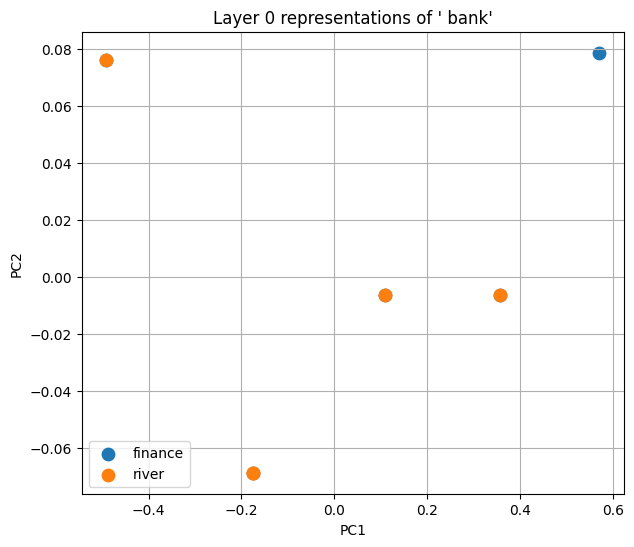

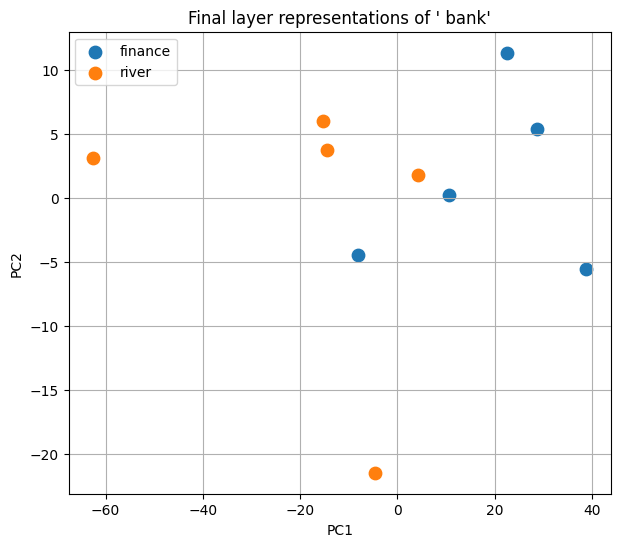

In [13]:
plot_pca(layer0_vectors, labels, "Layer 0 representations of ' bank'")
plot_pca(final_vectors, labels, "Final layer representations of ' bank'")